# ResNet18 Transfer Learning — Ant vs Bee Classification

This notebook is converted from the uploaded `resnet18 (1).py` file. It uses a pretrained ResNet18 model, freezes the pretrained layers, and trains the final classification layer on the Hymenoptera (ants and bees) dataset.

**Run in Google Colab:** select **Runtime → Change runtime type → T4 GPU** (optional but faster), then run the cells from top to bottom.

## 1. Download and extract the dataset

In [2]:
import urllib.request
import zipfile
from pathlib import Path

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
data_folder = Path("/content/data")
data_folder.mkdir(parents=True, exist_ok=True)

zip_path = data_folder / "hymenoptera_data.zip"
if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

dataset_path = data_folder / "hymenoptera_data"
if not dataset_path.exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(data_folder)

print("Dataset ready at:", dataset_path)
print("Train folder exists:", (dataset_path / "train").is_dir())
print("Validation folder exists:", (dataset_path / "val").is_dir())

Dataset ready at: \content\data\hymenoptera_data
Train folder exists: True
Validation folder exists: True


## 2. Import libraries and select device

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 3. Define image transformations and load data

In [5]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

train_data = datasets.ImageFolder(
    root=dataset_path / "train",
    transform=train_transform
)
val_data = datasets.ImageFolder(
    root=dataset_path / "val",
    transform=val_transform
)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader = DataLoader(val_data, batch_size=16, shuffle=False)

print("Classes:", train_data.classes)
print("Class-to-index mapping:", train_data.class_to_idx)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))

Classes: ['ants', 'bees']
Class-to-index mapping: {'ants': 0, 'bees': 1}
Training images: 244
Validation images: 153


## 4. Load pretrained ResNet18 and replace the classifier

In [6]:
# Load pretrained ImageNet weights.
# The first run may download the weights.
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the pretrained feature-extraction layers.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the final layer for the two dataset classes.
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(train_data.classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print("Trainable parameters:", trainable_parameters)
print("Classifier:", model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Sripada Pavankumar/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.4MB/s]


Trainable parameters: 1026
Classifier: Linear(in_features=512, out_features=2, bias=True)


## 5. Train the final classification layer

In [7]:
num_epochs = 5
train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    # Keep frozen feature layers in evaluation mode; train only the classifier.
    model.eval()
    model.fc.train()

    total_loss = 0.0
    correct_predictions = 0
    total_images = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        _, predicted = torch.max(outputs, 1)
        total_images += batch_size
        correct_predictions += (predicted == labels).sum().item()

    train_loss = total_loss / total_images
    train_accuracy = (correct_predictions / total_images) * 100
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2f}%")

Epoch 1/5
Train Loss: 0.4412 | Train Accuracy: 82.38%
Epoch 2/5
Train Loss: 0.2386 | Train Accuracy: 95.08%
Epoch 3/5
Train Loss: 0.1655 | Train Accuracy: 95.90%
Epoch 4/5
Train Loss: 0.1206 | Train Accuracy: 97.54%
Epoch 5/5
Train Loss: 0.1148 | Train Accuracy: 97.54%


## 6. Evaluate on the validation dataset

In [8]:
model.eval()
correct_predictions = 0
total_images = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predicted = torch.argmax(outputs, dim=1)

        total_images += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()

val_accuracy = (correct_predictions / total_images) * 100
print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Accuracy: 95.42%


## 7. Plot training metrics

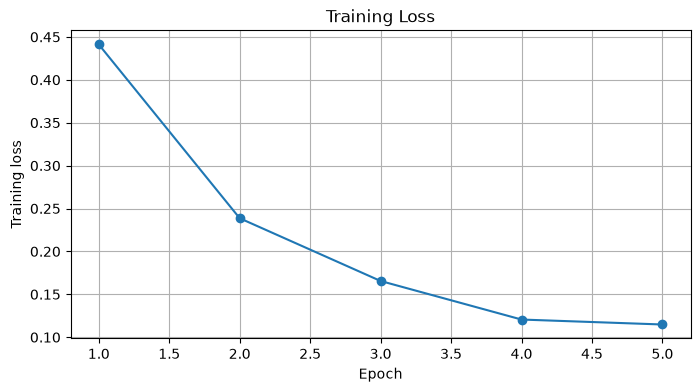

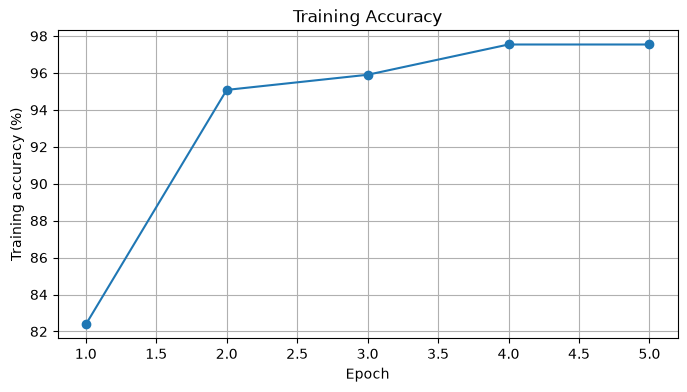

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, num_epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(1, num_epochs + 1), train_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training accuracy (%)")
plt.title("Training Accuracy")
plt.grid(True)
plt.show()

## 8. Upload an image and predict

The original script used image paths from Google Drive. This cell instead lets you upload an ant or bee image directly, so it works in a fresh Colab session without needing your personal Drive paths.

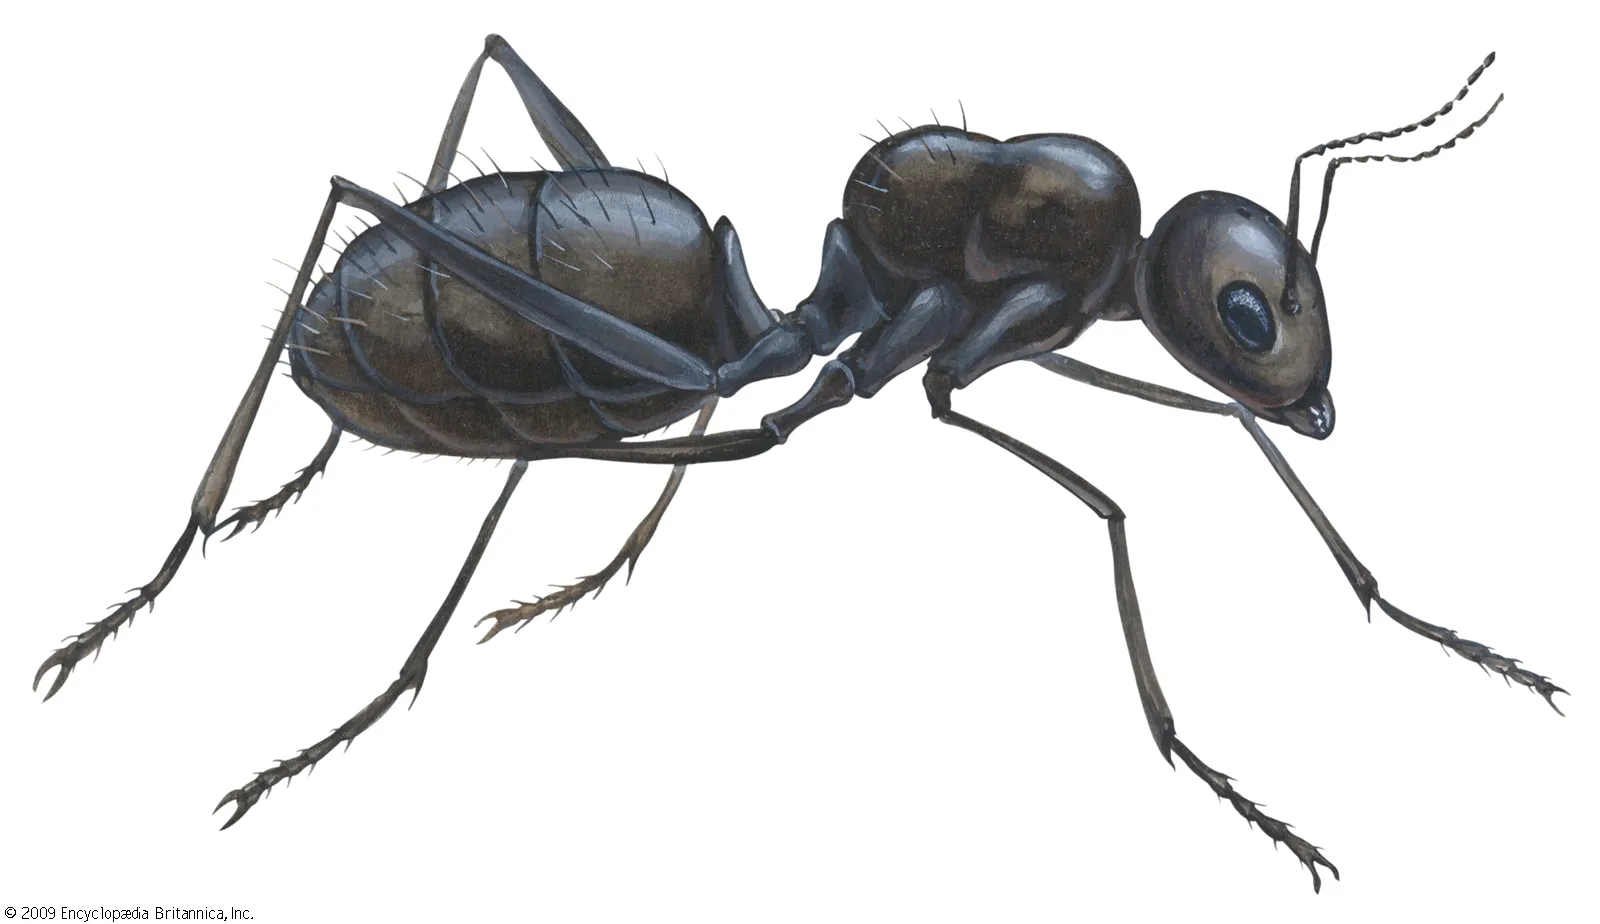

Predicted class: ants
Class probabilities:
  ants: 94.66%
  bees: 5.34%


In [12]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display
import torch

# Open a file picker to select an image
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

image_filename = filedialog.askopenfilename(
    title="Select an Ant or Bee Image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp *.jfif"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not image_filename:
    raise ValueError("No image selected. Please select an image file.")

# Load and display the selected image
image = Image.open(image_filename).convert("RGB")
display(image)

# Preprocess the image
input_tensor = val_transform(image).unsqueeze(0).to(device)

# Predict the class
model.eval()

with torch.no_grad():
    output = model(input_tensor)
    probabilities = torch.softmax(output, dim=1)[0]
    predicted_index = torch.argmax(probabilities).item()
    predicted_class = train_data.classes[predicted_index]

print("Predicted class:", predicted_class)
print("Class probabilities:")

for class_name, probability in zip(
    train_data.classes,
    probabilities.cpu().tolist()
):
    print(f"  {class_name}: {probability:.2%}")


## 9. Save the trained model weights

In [ ]:
from pathlib import Path
import torch

# Create the folder to store the model
model_folder = Path("saved_model")
model_folder.mkdir(parents=True, exist_ok=True)
# Set the model file path
model_path = model_folder / "ants_bees_resnet18.pth"

# Save the trained model and class information
torch.save({
    "model_state_dict": model.state_dict(),
    "classes": train_data.classes,
    "class_to_idx": train_data.class_to_idx,
}, model_path)

print("Model saved to:", model_path.resolve())
print("Classes:", train_data.classes)
print("File size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))

Model saved to: C:\Users\Sripada Pavankumar\Desktop\helo\ML_\pytorch_deploy\saved_model\resnet18_ant_bee.pth
Classes: ['ants', 'bees']
File size (MB): 42.71


### Notes
- This notebook preserves the original approach: pretrained ResNet18, frozen backbone, trainable final layer, 5 epochs, validation accuracy, and single-image prediction.
- The image uploaded for prediction should be an ant or bee image similar to the training dataset.
- The trained model is saved as a PyTorch checkpoint (`.pth`), not as a standalone TorchScript model.